# 04 — LSTM and GRU Models

**Project:** Learning the Path of the Storm — 24-hour tropical cyclone track forecasting
**Author:** Yatharth Vardan · AAI-590 Capstone, University of San Diego

**Rubric sections:** Model / Pipeline Design & Building, Model Training

So far, the best forecast comes from XGBoost, at **148.5 km** mean error on the validation seasons. Now it's
time for the main question of the project: can a recurrent neural network do better?

XGBoost sees a storm's history as one flat row of numbers. A recurrent network instead reads the history
*in order*, one 6-hour step at a time, carrying a memory of what it has seen so far. That's a natural fit
for a storm track, which is a sequence by nature. Here we build and train the two standard recurrent
designs:

- **LSTM** (Long Short-Term Memory; Hochreiter & Schmidhuber, 1997) uses gates to decide what to remember
  and what to forget at each step.
- **GRU** (Gated Recurrent Unit; Cho et al., 2014) is a slimmer variant with fewer gates and parameters.

To keep the comparison fair, both networks get the same 24 hours of history as the baselines, are scored on
the same forecast origins, and are judged on the same validation seasons. Tuning (longer histories, model
size, and so on) comes in the next notebook. As before, the test seasons stay locked away.

| | |
|---|---|
| **Input** | `data/processed/tracks_clean.csv.gz`; baseline errors from `preds_val_baselines.csv` |
| **Shared code** | `src/stormtrack/windows.py` (samples and sequences), `src/stormtrack/rnn.py` (model and training loop) |
| **Output** | `data/processed/preds_val_rnn.csv`, `models/*.pt`, figures `fig15`–`fig17` |

### Setting things up

Along with PyTorch, here we load the project's own pieces: the sample and sequence builders from
`windows.py`, and the model, loss and training loop from `rnn.py`. Keeping the model in a module means the
tuning notebook trains exactly the same network.

Training runs on the Mac's GPU through Apple's **MPS** backend when it's available, and falls back to the
CPU otherwise. CPU work is capped at 4 threads, so the laptop stays usable while models train.

In [1]:
# Imports and paths
import sys
import json
import inspect
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

from stormtrack.data_io import load_clean, PROCESSED
from stormtrack.windows import (build_samples, build_sequences, persistence_displacement, track_error_km,
                                to_latlon, TARGET_COLS, STEP_FEATURES, STATIC_COLS)
from stormtrack.rnn import RNNForecaster, distance_loss, train_model, predict

FIG_DIR, MODEL_DIR = ROOT / "reports" / "figures", ROOT / "models"
MODEL_DIR.mkdir(exist_ok=True)
torch.set_num_threads(4)
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
SEEDS = [42, 7, 2024]
print(f"PyTorch {torch.__version__} | training on: {DEVICE}")

pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})

def savefig(fig, name):
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    print(f"saved reports/figures/{name}")

PyTorch 2.15.0 | training on: mps


## 1. Turning each forecast into a sequence

First, we rebuild the same 76,613 forecast samples as in notebook 03, so that every model answers exactly
the same set of questions.

Then, for each sample, `build_sequences()` lays out the storm's history step by step, oldest first. With 4
fixes of history there are 3 six-hour steps, and each step carries 5 numbers:

| Step feature | Meaning |
|---|---|
| `dx`, `dy` | the 6-hour motion that brought the storm to this fix, in km east and north |
| `lat` | latitude at this fix |
| `wind_kt` | wind speed at this fix |
| `valid` | 1 if this step exists in the track; 0 if it's padding (only used with longer histories, in notebook 05) |

Alongside the sequence, a few **static** features describe the forecast as a whole rather than any single
step: longitude and time of year (as sine/cosine), distance to land, and the basin.

In [2]:
tracks = load_clean()
S = build_samples(tracks)
SEQ = build_sequences(tracks, S, n_steps=3)

BASINS = sorted(S["BASIN"].unique())
for b in BASINS:
    S[f"basin_{b}"] = (S["BASIN"] == b).astype(float)
STATIC = STATIC_COLS + [f"basin_{b}" for b in BASINS]

print(f"Samples: {len(S):,}   sequence array: {SEQ.shape} (samples, steps, features)")
print(f"Static features ({len(STATIC)}): {STATIC}")
print("\nOne example, oldest step first:")
pd.DataFrame(SEQ[0], columns=STEP_FEATURES, index=["step into t-12h", "step into t-6h", "step into now"]).round(1)

Samples: 76,613   sequence array: (76613, 3, 5) (samples, steps, features)
Static features (12): ['sin_lon', 'cos_lon', 'sin_doy', 'cos_doy', 'dist2land_km', 'basin_EP', 'basin_NA', 'basin_NI', 'basin_SA', 'basin_SI', 'basin_SP', 'basin_WP']

One example, oldest step first:


,dx,dy,lat,wind_kt,valid
step into t-12h,-10.900000,66.699997,-11.9,25.0,1.0
step into t-6h,10.900000,44.500000,-11.5,25.0,1.0
step into now,21.799999,33.400002,-11.2,30.0,1.0


So the sequence array holds 76,613 samples, each 3 steps long with 5 features per step, plus 12 static features per sample.

As a check, the example is the same first sample as in notebook 03, from Cyclone Peni. Its three steps carry exactly the motions XGBoost saw as `dx_m2 ... dy_m0` (for instance, 21.8 km east and 33.4 km north in the last step), now laid out in time order instead of side by side.

## 2. Targets and scaling

Next, we set up what the networks predict. Following notebook 03, the target is the **correction to
persistence**: the actual 24-hour displacement minus the straight-line forecast. The network only has to
learn how storms *depart* from a straight line, and its forecast is persistence plus that correction.

Neural networks train best when their inputs are on similar scales, so every feature is standardized
(minus its mean, divided by its standard deviation). One detail matters here: those means and standard
deviations come from the **training** seasons only. Using validation data to set them would quietly leak
information about the seasons we evaluate on. The `valid` flag is left as a plain 0/1.

In [3]:
is_tr, is_va = S["split"].eq("train").to_numpy(), S["split"].eq("val").to_numpy()
P = persistence_displacement(S)
Y = S[TARGET_COLS].to_numpy() - P                       # correction to persistence, km

seq_mu = SEQ[is_tr].reshape(-1, SEQ.shape[2]).mean(0); seq_sd = SEQ[is_tr].reshape(-1, SEQ.shape[2]).std(0)
seq_mu[-1], seq_sd[-1] = 0.0, 1.0                       # leave the 0/1 'valid' flag as is
ST = S[STATIC].to_numpy()
st_mu, st_sd = ST[is_tr].mean(0), ST[is_tr].std(0)
st_sd[st_sd == 0] = 1.0
y_scale = Y[is_tr].std(0)

def tensors(mask):
    return (torch.tensor((SEQ[mask] - seq_mu) / seq_sd, dtype=torch.float32),
            torch.tensor((ST[mask] - st_mu) / st_sd, dtype=torch.float32),
            torch.tensor(Y[mask] / y_scale, dtype=torch.float32))

train_t, val_t = tensors(is_tr), tensors(is_va)
va = S[is_va].reset_index(drop=True)
P_va = P[is_va]
print(f"train: {len(train_t[0]):,} samples   val: {len(val_t[0]):,} samples")
print(f"Target scale (km): east {y_scale[0]:.0f}, north {y_scale[1]:.0f}")

train: 65,169 samples   val: 4,699 samples
Target scale (km): east 156, north 129


## 3. The model

Here's the network, printed straight from `src/stormtrack/rnn.py` so you can see exactly what gets trained.
It has three parts:

1. **A recurrent layer** (LSTM or GRU) reads the 3 history steps in order. Its final hidden state is a
   compact summary of how the storm has been moving.
2. **That summary is joined with the static features**, which don't change along the window.
3. **A small two-layer network (the "head")** turns the combined vector into a 24-hour correction, east and
   north.

In [4]:
print(inspect.getsource(RNNForecaster))

class RNNForecaster(nn.Module):
    """Sequence encoder + static context + small MLP head.

    The recurrent layer (LSTM or GRU) reads the storm's recent history one 6-hour
    step at a time. Its final hidden state, a summary of how the storm has been
    moving, is joined with features that do not change along the window (location,
    season, land distance, basin), and a two-layer MLP turns that into a 24-hour
    correction to the persistence forecast (east and north, scaled units).
    """

    def __init__(self, n_step_features, n_static, cell="lstm", hidden=64, layers=1, dropout=0.1):
        super().__init__()
        rnn_cls = {"lstm": nn.LSTM, "gru": nn.GRU}[cell]
        self.rnn = rnn_cls(n_step_features, hidden, num_layers=layers, batch_first=True,
                           dropout=dropout if layers > 1 else 0.0)
        self.head = nn.Sequential(
            nn.Linear(hidden + n_static, hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, 2),
        )

To get a feel for the size, the cell below builds one LSTM and one GRU with 64 hidden units and counts
their trainable parameters. As a rule of thumb, a GRU has about three-quarters of an LSTM's recurrent
weights, since it has three gate blocks instead of four.

In [5]:
n_step, n_static = SEQ.shape[2], len(STATIC)
for cell in ["lstm", "gru"]:
    m = RNNForecaster(n_step, n_static, cell=cell, hidden=64)
    print(f"{cell.upper():4s}: {sum(p.numel() for p in m.parameters()):,} trainable parameters")

LSTM: 23,234 trainable parameters
GRU : 18,690 trainable parameters


## 4. Training setup

Before training, two choices are worth explaining.

**First, the loss function.** Most regression models minimize squared error, as XGBoost did in notebook 03. But
the way forecasts are judged is the *distance* between forecast and actual position. So here, the loss is
the mean Euclidean distance in km between predicted and actual displacement, which, over a few hundred km,
is practically the same as the great-circle error. In other words, the network is trained on the very
number it's graded on.

In [6]:
print(inspect.getsource(distance_loss))

def distance_loss(pred_scaled, target_scaled, y_scale):
    """Mean Euclidean distance in km between predicted and true displacement.

    Predictions and targets are in scaled units; multiplying back by y_scale gives km,
    so the loss is (very nearly) the great-circle track error the models are judged on.
    """
    diff = (pred_scaled - target_scaled) * y_scale
    return torch.sqrt((diff ** 2).sum(dim=1) + 1e-6).mean()



**Second, the training loop.** Here, `train_model()` uses the AdamW optimizer, with a learning rate of 0.001, batches of
512 forecasts, and gradient clipping to keep updates stable. After every pass over the training data (an
**epoch**), it checks the validation loss:

- If validation stops improving for 4 epochs, the learning rate is halved.
- If it stops improving for 10 epochs, training ends (early stopping), and the weights from the best epoch
  are kept.

So, as with XGBoost's early stopping, the amount of training is chosen automatically rather than fixed by
hand.

## 5. Training the LSTM

Now let's train. For a first look, the cell below trains one LSTM (64 hidden units, one layer, seed 42) and
prints its progress every 10 epochs. Each epoch takes well under a second.

In [7]:
torch.manual_seed(SEEDS[0])
lstm, lstm_hist = train_model(RNNForecaster(n_step, n_static, "lstm", hidden=64), train_t, val_t,
                              y_scale, DEVICE, seed=SEEDS[0])
lstm_hist = pd.DataFrame(lstm_hist)
print(f"Epochs run: {len(lstm_hist)}   best validation loss: {lstm_hist['val_km'].min():.1f} km "
      f"(epoch {lstm_hist['val_km'].idxmin() + 1})   time: {lstm_hist['secs'].sum():.0f} s")

  epoch   1  train  156.3 km  val  156.5 km


  epoch  10  train  146.1 km  val  150.5 km


  epoch  20  train  144.2 km  val  148.4 km


  epoch  30  train  143.0 km  val  148.1 km


  epoch  40  train  142.4 km  val  147.8 km


  early stop at epoch 49; best val 147.7 km
Epochs run: 49   best validation loss: 147.7 km (epoch 39)   time: 23 s


## 6. Training the GRU

Next, the GRU, with exactly the same settings and seed, so that the only difference between the two runs
is the recurrent cell.

In [8]:
torch.manual_seed(SEEDS[0])
gru, gru_hist = train_model(RNNForecaster(n_step, n_static, "gru", hidden=64), train_t, val_t,
                            y_scale, DEVICE, seed=SEEDS[0])
gru_hist = pd.DataFrame(gru_hist)
print(f"Epochs run: {len(gru_hist)}   best validation loss: {gru_hist['val_km'].min():.1f} km "
      f"(epoch {gru_hist['val_km'].idxmin() + 1})   time: {gru_hist['secs'].sum():.0f} s")

  epoch   1  train  156.0 km  val  156.7 km


  epoch  10  train  146.0 km  val  150.0 km


  epoch  20  train  144.0 km  val  147.9 km


  epoch  30  train  142.8 km  val  147.3 km


  epoch  40  train  142.1 km  val  147.2 km


  epoch  50  train  141.9 km  val  147.1 km


  epoch  60  train  141.8 km  val  147.0 km


  early stop at epoch 66; best val 146.9 km
Epochs run: 66   best validation loss: 146.9 km (epoch 56)   time: 31 s


To see how training went, Figure 15 plots both learning curves: training loss and validation loss after
every epoch, with the best epoch marked. Two things are worth watching for. One is whether validation keeps
improving or flattens out; the other is whether the training loss pulls far below the validation loss,
which would be a sign of overfitting.

saved reports/figures/fig15_rnn_learning_curves.png


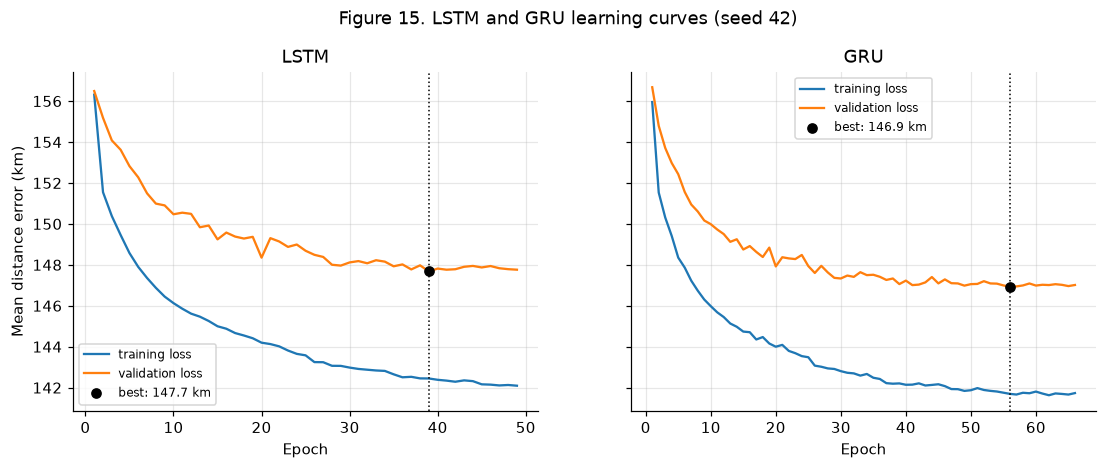

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (name, h) in zip(axes, [("LSTM", lstm_hist), ("GRU", gru_hist)]):
    ax.plot(h["epoch"], h["train_km"], label="training loss")
    ax.plot(h["epoch"], h["val_km"], label="validation loss")
    b = h["val_km"].idxmin()
    ax.axvline(h.loc[b, "epoch"], color="k", ls=":", lw=1)
    ax.scatter(h.loc[b, "epoch"], h.loc[b, "val_km"], color="k", zorder=3, label=f"best: {h.loc[b, 'val_km']:.1f} km")
    ax.set(title=name, xlabel="Epoch")
    ax.legend(fontsize=8)
axes[0].set_ylabel("Mean distance error (km)")
fig.suptitle("Figure 15. LSTM and GRU learning curves (seed 42)", y=1.02)
savefig(fig, "fig15_rnn_learning_curves.png")
plt.show()

Both curves tell a healthy story. Validation loss drops quickly over the first 10 epochs, then flattens out, and early stopping catches the plateau: the LSTM's best epoch is 39 (147.7 km) and the GRU's is 56 (146.9 km). The training loss does settle about 5 km below the validation loss. However, since the validation curve levels off rather than turning back up, this looks like the normal gap between seasons the model has seen and seasons it hasn't, rather than real overfitting.

Even a single run of either network already edges past XGBoost's 148.5 km.

## 7. Is the result stable across random seeds?

A single training run can be lucky or unlucky. Neural networks start from random weights and see batches in
random order, so the same model trained twice can land on slightly different results. Before reading too
much into one run, it's worth checking how big that variation is.

So in the next cell, we train each cell type with two more seeds (7 and 2024), and score all six models on
the validation seasons with the same `track_error_km()` used for the baselines. We also score an
**ensemble** that averages each cell type's three forecasts. Averaging smooths out the quirks of individual
runs, and it's a cheap, standard way to get a more reliable model.

In [10]:
def forecast(model, tensors_):
    return predict(model, tensors_[0], tensors_[1], DEVICE) * y_scale + P_va   # back to km, add persistence

runs, preds = [], {}
for cell, first in [("lstm", lstm), ("gru", gru)]:
    preds[cell] = []
    for seed in SEEDS:
        if seed == SEEDS[0]:
            model = first
        else:
            torch.manual_seed(seed)
            model, _ = train_model(RNNForecaster(n_step, n_static, cell, hidden=64), train_t, val_t,
                                   y_scale, DEVICE, seed=seed, verbose=False)
        torch.save(model.state_dict(), MODEL_DIR / f"{cell}_seed{seed}.pt")
        p = forecast(model, val_t)
        preds[cell].append(p)
        runs.append({"model": cell.upper(), "seed": seed, "mean_km": track_error_km(va, p).mean()})

seed_tab = pd.DataFrame(runs)
display(seed_tab.pivot(index="seed", columns="model", values="mean_km").round(1))
agg = seed_tab.groupby("model")["mean_km"].agg(["mean", "std", "min", "max"]).round(1)
agg

model,GRU,LSTM
seed,,
7,145.5,146.5
42,145.8,146.5
2024,145.7,146.3


,mean,std,min,max
model,,,,
GRU,145.7,0.1,145.5,145.8
LSTM,146.4,0.1,146.3,146.5


Reassuringly, the variation between seeds is tiny. The three GRUs land between 145.5 and 145.8 km, and the three LSTMs between 146.3 and 146.5 km, a spread of about 0.1 km either way. So the gap between the two cell types (about 0.7 km) is larger than the noise from random starts, and every single run beats XGBoost.

## 8. How do they compare with the baselines?

Now for the main comparison. In the cell below, we load the per-forecast validation errors of the four
baselines saved by notebook 03, line them up with the neural networks' forecasts, and build the same summary
table as before. Each network appears as its 3-seed ensemble.

In [11]:
base = pd.read_csv(PROCESSED / "preds_val_baselines.csv", parse_dates=["ISO_TIME"])
assert (base["SEG_ID"].to_numpy() == va["SEG_ID"].to_numpy()).all() and \
       (base["ISO_TIME"].to_numpy() == va["ISO_TIME"].to_numpy()).all(), "forecasts not aligned"

err = {"No motion": base["err_no_motion_km"].to_numpy(), "Persistence": base["err_persistence_km"].to_numpy(),
       "Linear regression": base["err_linear_regression_km"].to_numpy(), "XGBoost": base["err_xgboost_km"].to_numpy(),
       "LSTM (3-seed ensemble)": track_error_km(va, np.mean(preds["lstm"], axis=0)),
       "GRU (3-seed ensemble)": track_error_km(va, np.mean(preds["gru"], axis=0))}
na = va["BASIN"].eq("NA").to_numpy()
summary = pd.DataFrame({m: {"mean_km": e.mean(), "median_km": np.median(e), "p90_km": np.percentile(e, 90),
                            "NA_mean_km": e[na].mean()} for m, e in err.items()}).T
summary["skill_vs_persistence_%"] = 100 * (1 - summary["mean_km"] / summary.loc["Persistence", "mean_km"])
summary.round(1)

,mean_km,median_km,p90_km,NA_mean_km,skill_vs_persistence_%
No motion,391.1,371.6,644.5,461.6,-132.9
Persistence,168.0,139.2,320.3,182.9,0.0
Linear regression,158.3,133.0,298.9,166.0,5.7
XGBoost,148.5,126.4,277.2,163.7,11.6
LSTM (3-seed ensemble),146.0,125.3,276.3,156.6,13.0
GRU (3-seed ensemble),145.2,123.4,273.1,155.9,13.5


Here's the headline. Both recurrent networks beat every baseline:

- **GRU ensemble:** 145.2 km, which is 13.5% better than persistence.
- **LSTM ensemble:** 146.0 km, 13.0% better.
- **XGBoost**, for comparison, was 148.5 km (11.6%).

Averaging the three seeds also helps a little, about half a km compared with a typical single run.

Notably, the clearest gain is on the **North Atlantic**, where XGBoost and linear regression were close. There, both networks come in around 156 km, compared with 164 km for XGBoost. Across all basins, the improvement over XGBoost is a modest 2.5 to 3.3 km on average, and the GRU beats XGBoost on 54% of individual forecasts.

As with the baselines, a gap in averages needs checking against chance. So the cell below reruns the
storm-level **paired bootstrap** from notebook 03: it resamples whole validation storms 2,000 times and gives
a 95% interval for the difference in mean error. A positive number means the second model is better.

In [12]:
def paired_bootstrap(err_a, err_b, groups, n_boot=2000, seed=42):
    diff = pd.DataFrame({"g": groups, "d": err_a - err_b}).groupby("g")["d"].agg(["sum", "size"])
    s, n = diff["sum"].to_numpy(), diff["size"].to_numpy()
    idx = np.random.default_rng(seed).integers(0, len(s), size=(n_boot, len(s)))
    boots = s[idx].sum(axis=1) / n[idx].sum(axis=1)
    return s.sum() / n.sum(), *np.percentile(boots, [2.5, 97.5])

pairs = [("Persistence", "LSTM (3-seed ensemble)"), ("XGBoost", "LSTM (3-seed ensemble)"),
         ("XGBoost", "GRU (3-seed ensemble)"), ("GRU (3-seed ensemble)", "LSTM (3-seed ensemble)")]
pd.DataFrame([{"comparison": f"{a} minus {b}",
               **dict(zip(["mean_diff_km", "ci_low_km", "ci_high_km"], paired_bootstrap(err[a], err[b], va["SID"])))}
              for a, b in pairs]).set_index("comparison").round(1)

,mean_diff_km,ci_low_km,ci_high_km
comparison,,,
Persistence minus LSTM (3-seed ensemble),21.9,18.4,25.6
XGBoost minus LSTM (3-seed ensemble),2.5,0.9,4.1
XGBoost minus GRU (3-seed ensemble),3.3,1.7,5.0
GRU (3-seed ensemble) minus LSTM (3-seed ensemble),-0.8,-1.3,-0.4


Taking the bootstrap results one at a time:

- **Against XGBoost**, both gains hold up. The GRU is better by 3.3 km (95% interval 1.7 to 5.0 km), and the LSTM by 2.5 km (0.9 to 4.1 km). Neither interval touches zero, so the networks really are better on these seasons, even if not by much.
- **Against persistence**, the LSTM's gain is about 22 km per forecast.
- **GRU versus LSTM**, the GRU's edge is just 0.8 km, small but consistent (interval 0.4 to 1.3 km).

One caveat deserves a clear mention. The networks differ from XGBoost in *two* ways: they read the history as a sequence, and they're trained directly on distance error, while XGBoost was trained on squared error. Right now, we can't tell how much of the gain comes from each. Pulling those two apart is the first experiment in the tuning notebook.

## 9. Where do the networks help?

Next, the same breakdown by latitude as in notebook 03, now with the two networks added (Figure 16). The
question is whether the recurrent models improve on XGBoost in the recurvature zone, beyond 25°, where
errors are largest.

saved reports/figures/fig16_error_by_latitude_rnn.png


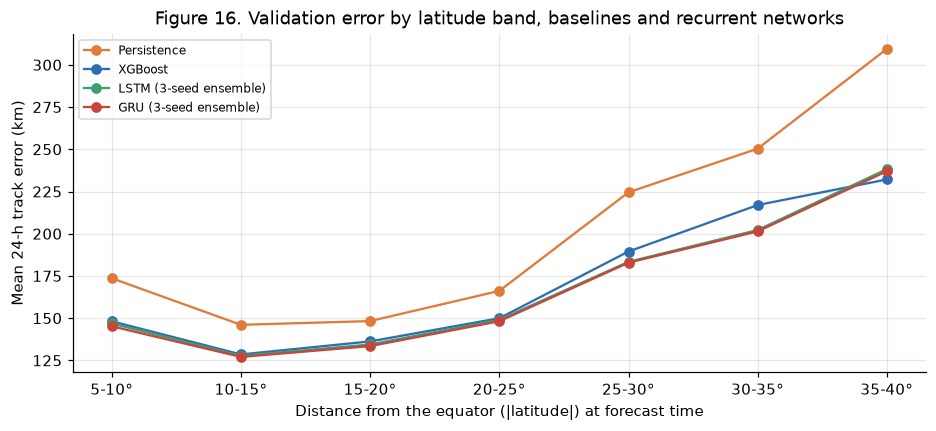

,Persistence,XGBoost,LSTM (3-seed ensemble),GRU (3-seed ensemble)
LAT,,,,
5,174.0,148.0,147.0,145.0
10,146.0,129.0,128.0,127.0
15,148.0,136.0,134.0,133.0
20,166.0,150.0,149.0,148.0
25,225.0,189.0,183.0,183.0
30,250.0,217.0,202.0,201.0
35,309.0,232.0,238.0,237.0


In [13]:
show_models = ["Persistence", "XGBoost", "LSTM (3-seed ensemble)", "GRU (3-seed ensemble)"]
colors = {"Persistence": "#E07B39", "XGBoost": "#2F6DB3", "LSTM (3-seed ensemble)": "#3A9E6F", "GRU (3-seed ensemble)": "#C9453B"}
bands = (va["LAT"].abs() // 5 * 5).astype(int)
by_band = pd.DataFrame({m: err[m] for m in show_models}).groupby(bands).agg(["mean", "size"])
by_band = by_band[by_band[("Persistence", "size")] >= 50]

fig, ax = plt.subplots(figsize=(10, 4))
labels = [f"{b}-{b+5}°" for b in by_band.index]
for m in show_models:
    ax.plot(labels, by_band[(m, "mean")], "o-", color=colors[m], label=m)
ax.set(xlabel="Distance from the equator (|latitude|) at forecast time", ylabel="Mean 24-h track error (km)",
       title="Figure 16. Validation error by latitude band, baselines and recurrent networks")
ax.legend(fontsize=8)
savefig(fig, "fig16_error_by_latitude_rnn.png")
plt.show()
by_band.xs("mean", axis=1, level=1).round(0)

Looking at the figure, below 25° from the equator all four learned models are close, and the networks gain only 1 to 2 km over XGBoost. The real difference shows up in the recurvature zone. At 25–30°, XGBoost averages 189 km and both networks 183 km, and at 30–35° it's 217 km against about 202 km. Overall, from 25° outward, the GRU cuts XGBoost's error from about 203 km to 194 km.

At 35–40°, XGBoost is slightly ahead again (232 versus 237 km). With only 68 forecasts in that band, though, the difference there is within noise. So the pattern supports the original idea: reading the history step by step helps most where storms are turning.

## 10. Hurricane Jose again

Finally, back to the hard case from notebook 03. Hurricane Jose (2017) looped slowly near 25–30°N, and both
persistence and XGBoost missed the loop. Here we draw XGBoost's and the LSTM ensemble's forecasts every 12
hours along Jose's track (Figure 17), to see whether reading the history as a sequence makes any visible
difference.

saved reports/figures/fig17_jose_xgb_vs_lstm.png


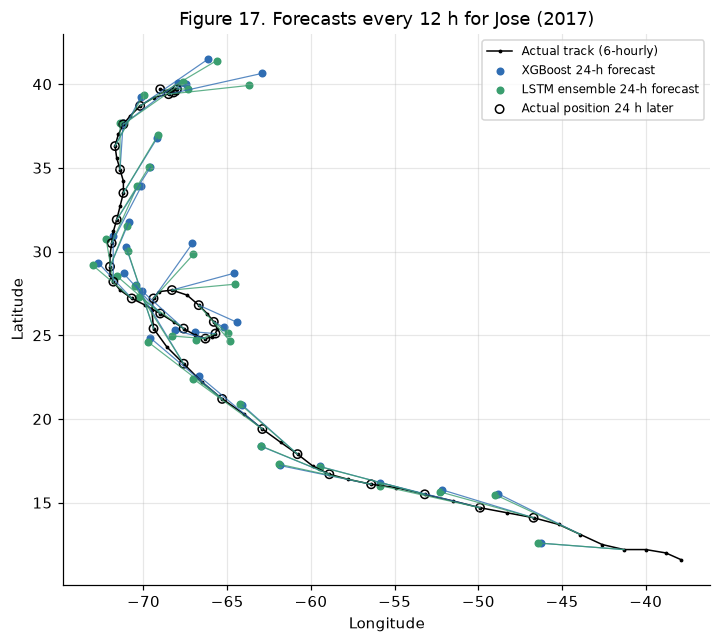

Mean error on Jose: persistence 163 km, XGBoost 153 km, LSTM ensemble 144 km, GRU ensemble 141 km


In [14]:
seg = "2017247N09327_1"
lstm_disp = np.mean(preds["lstm"], axis=0)
va["lat_l"], va["lon_l"] = to_latlon(va["LAT"], va["LON"], lstm_disp[:, 0], lstm_disp[:, 1])
trk = tracks[tracks["SEG_ID"] == seg]
fc = va[va["SEG_ID"] == seg]
step = fc.index[::2]

# XGBoost positions come from notebook 03's saved predictions (no need to load XGBoost alongside PyTorch)
lat_x, lon_x = base.loc[step, "pred_lat_xgboost"].to_numpy(), base.loc[step, "pred_lon_xgboost"].to_numpy()

fig, ax = plt.subplots(figsize=(8, 6.5))
ax.plot(trk["LON"], trk["LAT"], "k.-", lw=1, ms=3, label="Actual track (6-hourly)")
for k, i in enumerate(step):
    r = va.loc[i]
    ax.plot([r["LON"], lon_x[k]], [r["LAT"], lat_x[k]], color="#2F6DB3", lw=0.8, alpha=0.8)
    ax.plot([r["LON"], r["lon_l"]], [r["LAT"], r["lat_l"]], color="#3A9E6F", lw=0.8, alpha=0.8)
ax.scatter(lon_x, lat_x, color="#2F6DB3", s=18, label="XGBoost 24-h forecast")
ax.scatter(va.loc[step, "lon_l"], va.loc[step, "lat_l"], color="#3A9E6F", s=18, label="LSTM ensemble 24-h forecast")
ax.scatter(va.loc[step, "lon_true"], va.loc[step, "lat_true"], facecolor="none", edgecolor="k", s=30,
           label="Actual position 24 h later")
ax.set(xlabel="Longitude", ylabel="Latitude", aspect="equal", title="Figure 17. Forecasts every 12 h for Jose (2017)")
ax.legend(fontsize=8)
savefig(fig, "fig17_jose_xgb_vs_lstm.png")
plt.show()
jose = va["SEG_ID"].eq(seg).to_numpy()
print(f"Mean error on Jose: persistence {err['Persistence'][jose].mean():.0f} km, XGBoost {err['XGBoost'][jose].mean():.0f} km, "
      f"LSTM ensemble {err['LSTM (3-seed ensemble)'][jose].mean():.0f} km, GRU ensemble {err['GRU (3-seed ensemble)'][jose].mean():.0f} km")

Up close, Jose shows the same thing on a small scale. Along the straight westward run, XGBoost's and the LSTM's forecasts almost sit on top of each other. Inside the loop near 25–30°N, the LSTM's forecasts stay somewhat closer to the actual positions. The improvement is visible in the averages, too: 163 km for persistence, 153 km for XGBoost, 144 km for the LSTM ensemble and 141 km for the GRU ensemble.

Still, neither network truly *anticipates* the loop. Both keep projecting Jose onward and only catch up once the turn shows in the track. That's the natural limit of a model that sees only the storm's own past, and no information about the surrounding weather that actually steers it.

## 11. Save predictions and settings

Last, we save what the next notebooks need. Each validation forecast's error for both ensembles goes into
`preds_val_rnn.csv`, next to the baseline file, for the final analysis. The scaling statistics are saved
too, because any future forecast has to be scaled with exactly the same numbers the networks were trained
with. The six trained models were already saved during the seed runs.

In [15]:
out = va[["SID", "SEG_ID", "BASIN", "SEASON", "ISO_TIME"]].copy()
out["err_lstm_ens_km"] = err["LSTM (3-seed ensemble)"]
out["err_gru_ens_km"] = err["GRU (3-seed ensemble)"]
out.to_csv(PROCESSED / "preds_val_rnn.csv", index=False)

scaling = {"n_steps": 3, "hidden": 64, "seeds": SEEDS, "static_features": STATIC, "step_features": STEP_FEATURES,
           "seq_mu": seq_mu.tolist(), "seq_sd": seq_sd.tolist(), "st_mu": st_mu.tolist(), "st_sd": st_sd.tolist(),
           "y_scale": y_scale.tolist()}
(MODEL_DIR / "rnn_config.json").write_text(json.dumps(scaling, indent=2))
print("saved data/processed/preds_val_rnn.csv, models/rnn_config.json and",
      ", ".join(sorted(p.name for p in MODEL_DIR.glob("*.pt"))))

saved data/processed/preds_val_rnn.csv, models/rnn_config.json and gru_seed2024.pt, gru_seed42.pt, gru_seed7.pt, lstm_seed2024.pt, lstm_seed42.pt, lstm_seed7.pt


## Summary

So, where do things stand after the first round of neural networks? Here is the full picture on the validation seasons (2017–2019):

| Model | Mean error | Median | 90th pct | North Atlantic | Skill vs persistence |
|---|---|---|---|---|---|
| Persistence | 168.0 km | 139 km | 320 km | 183 km | 0% |
| Linear regression | 158.3 km | 133 km | 299 km | 166 km | 5.7% |
| XGBoost | 148.5 km | 126 km | 277 km | 164 km | 11.6% |
| LSTM (3-seed ensemble) | 146.0 km | 125 km | 276 km | 157 km | 13.0% |
| **GRU (3-seed ensemble)** | **145.2 km** | **123 km** | **273 km** | **156 km** | **13.5%** |

In short:

- **Both recurrent networks beat XGBoost.** The margin is modest (2.5–3.3 km on average), but the bootstrap shows it is real.
- **The gains come where turns happen.** They're concentrated at 25–35° latitude and in the North Atlantic.
- **GRU slightly ahead.** The GRU edges out the LSTM with about 20% fewer parameters, and results barely move between seeds.
- **Training is cheap.** Each network trains in under a minute on the Mac's GPU.

With only 3 steps of history and default settings, the networks haven't been pushed yet. So notebook 05 takes up the open questions:

1. Is the gain from the sequence structure or from the distance loss?
2. Does a longer history (2 or 3 days instead of 1) help, now that the `valid` flag lets every model keep the same forecast origins?
3. What hidden size and depth work best?

Once again, every choice will be made on the validation seasons, with the test seasons kept for the final verdict.

**In production**, the trained GRU would run alongside XGBoost every 6 hours. It needs the same four latest fixes, the scaling numbers saved in `rnn_config.json`, and a fraction of a second on a CPU.

## References

Cho, K., van Merriënboer, B., Gulcehre, C., Bahdanau, D., Bougares, F., Schwenk, H., & Bengio, Y. (2014).
Learning phrase representations using RNN encoder–decoder for statistical machine translation. In
*Proceedings of the 2014 Conference on Empirical Methods in Natural Language Processing* (pp. 1724–1734).
https://doi.org/10.3115/v1/D14-1179

Hochreiter, S., & Schmidhuber, J. (1997). Long short-term memory. *Neural Computation, 9*(8), 1735–1780.
https://doi.org/10.1162/neco.1997.9.8.1735

Loshchilov, I., & Hutter, F. (2019). Decoupled weight decay regularization. In *International Conference on
Learning Representations*. https://openreview.net/forum?id=Bkg6RiCqY7

Paszke, A., Gross, S., Massa, F., Lerer, A., Bradbury, J., Chanan, G., ... Chintala, S. (2019). PyTorch: An
imperative style, high-performance deep learning library. In *Advances in Neural Information Processing
Systems 32* (pp. 8024–8035).

*AI-tool disclosure: Claude (Anthropic) helped draft this notebook's code and explanations. The author
reviewed each step, ran the notebook, and checked the outputs.*